In [1]:
import pandas as pd
import matplotlib.pyplot as pl
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay
import seaborn as sns

In [2]:
df = pd.read_csv('./dataset/loan_approval_nepal_clean_v2.csv')

In [3]:
df.shape

(70, 6)

In [4]:
df.head()

,name,age,monthly_income_npr,credit_score,existing_loans,loan_status
0,Purnima Bhandari,28,31049,357,1,Not Approved
1,Laxmi Yadav,55,17082,307,1,Not Approved
2,Bikram Bogati,53,50713,407,1,Not Approved
3,Devi Ghimire,38,25463,478,2,Not Approved
4,Ram Bhandari,30,72059,516,1,Hold


In [5]:
scaler = StandardScaler()
df['monthly_income_npr'] = scaler.fit_transform(df[['monthly_income_npr']])
df['credit_score'] = scaler.fit_transform(df[['credit_score']])

In [6]:
X = df[['monthly_income_npr','credit_score']]

In [7]:
Y= df['loan_status']

In [8]:
# model = SVC(kernel='linear',C=1)

<Axes: xlabel='monthly_income_npr', ylabel='credit_score'>

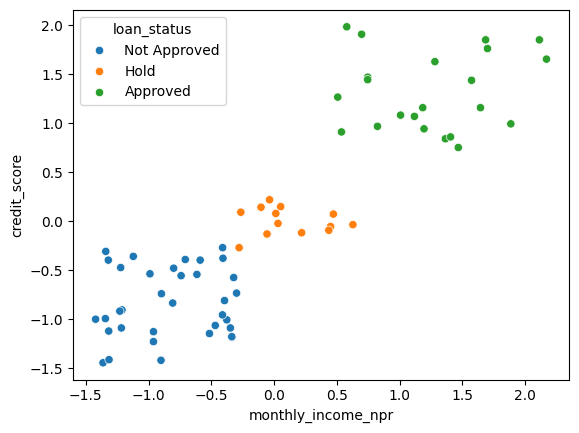

In [9]:
sns.scatterplot(x=df['monthly_income_npr'],y=df['credit_score'],hue=df['loan_status'])

In [10]:
model = LogisticRegression()


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
)

In [12]:
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [13]:
y_pred = model.predict(X_test)

In [14]:
len(y_pred)

14

In [15]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
              precision    recall  f1-score   support

    Approved       1.00      1.00      1.00         2
        Hold       1.00      1.00      1.00         5
Not Approved       1.00      1.00      1.00         7

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14



x_test

In [16]:
y_test

22            Hold
0     Not Approved
49        Approved
4             Hold
54            Hold
18    Not Approved
10    Not Approved
33    Not Approved
45            Hold
12            Hold
31    Not Approved
9     Not Approved
67        Approved
5     Not Approved
Name: loan_status, dtype: str

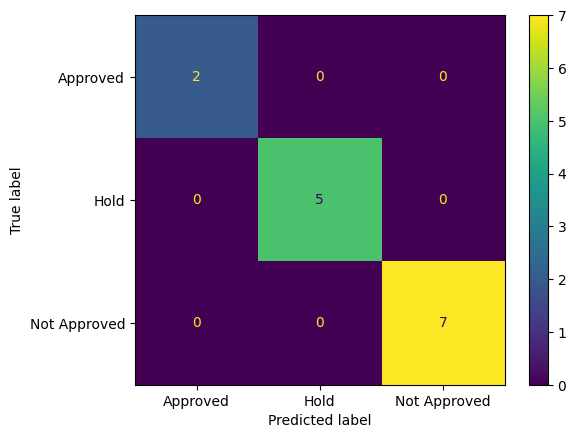

In [17]:
cm = confusion_matrix(y_test,y_pred,labels=model.classes_)
ConfusionMatrixDisplay(confusion_matrix =cm,display_labels = model.classes_).plot()

In [18]:
X_test_view = X_test.copy()
X_test_view['output']=y_test
X_test_view


,monthly_income_npr,credit_score,output
22,-0.103724,0.143164,Hold
0,-0.960627,-1.126180,Not Approved
49,2.114057,1.850431,Approved
4,0.219730,-0.117052,Hold
54,0.472668,0.073350,Hold
18,-1.221854,-0.472468,Not Approved
10,-1.317065,-1.119833,Not Approved
33,-0.514589,-1.145220,Not Approved
45,0.628350,-0.034544,Hold
12,0.450333,-0.053584,Hold


In [19]:
y_pred

array(['Hold', 'Not Approved', 'Approved', 'Hold', 'Hold', 'Not Approved',
       'Not Approved', 'Not Approved', 'Hold', 'Hold', 'Not Approved',
       'Not Approved', 'Approved', 'Not Approved'], dtype=object)